<a href="https://colab.research.google.com/github/ramadasusiri2806-boop/flipkart_webscrapping_EDA/blob/main/Spam_and_Ham_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spam and Ham Message Classification

## Project Overview
This project builds a machine learning system to classify SMS messages as **spam** or **ham**.

### Dataset
- **Category**: target label (`spam` or `ham`)
- **Message**: text message to classify

### Project Sprints
1. **Sprint 0:** EDA with basic plots
2. **Sprint 1:** Text preprocessing and feature engineering
3. **Sprint 2:** Machine learning model development and evaluation
4. **Sprint 3:** NLP architecture development and evaluation
5. **Sprint 4:** Model deployment

> **Note:** Run the notebook cells from top to bottom. The notebook is designed to work with the uploaded `spam.csv` file.


# Sprint 0 – Exploratory Data Analysis (EDA)

## 1. Understand the Data

The dataset contains SMS messages and their corresponding labels. The objective is to learn patterns that distinguish unwanted spam messages from normal messages.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("spam.csv", encoding="latin-1")

print("Shape of dataset:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Shape of dataset: (5572, 2)

Columns:
['Category', 'Message']

First 5 rows:


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# Basic information
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["Category"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
Category    0
Message     0
dtype: int64

Duplicate rows: 415

Class distribution:
Category
ham     4825
spam     747
Name: count, dtype: int64


## 2. Problem Statement

### Problem Statement
The goal is to develop a machine learning and NLP-based system that automatically classifies an SMS message as **spam** or **ham**.

### Questions this project can answer
- How many messages are spam and how many are ham?
- Is the dataset balanced or imbalanced?
- Do spam messages have different lengths from ham messages?
- Which words or patterns are common in spam messages?
- Can machine learning accurately classify unseen messages?
- Which evaluation metrics are useful for a spam detection system?


## 3. Data Cleaning and Manipulation

The dataset contains the required two columns. We remove unnecessary columns if they exist, remove missing records, remove duplicate messages, and normalize the text column.


In [ ]:
# Keep only the required columns
df = df[["Category", "Message"]].copy()

# Remove missing values
df.dropna(subset=["Category", "Message"], inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Standardize data types
df["Category"] = df["Category"].astype(str).str.lower().str.strip()
df["Message"] = df["Message"].astype(str)

print("Shape after cleaning:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Shape after cleaning: (5157, 2)

Missing values:
Category    0
Message     0
dtype: int64

Duplicate rows: 0


## 4. Identify Data Types

- **Category** is a categorical nominal variable because it contains two classes: spam and ham.
- **Message** is a textual categorical/unstructured variable.
- After feature engineering, numerical variables such as message length and word count can be created.
- There are no continuous variables in the original dataset.
- There are no ordinal variables in the original dataset.


In [ ]:
# Create numerical text features for EDA
df["message_length"] = df["Message"].str.len()
df["word_count"] = df["Message"].str.split().str.len()

display(df.head())
print(df[["message_length", "word_count"]].describe())


,Category,Message,message_length,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


       message_length   word_count
count     5157.000000  5157.000000
mean        79.228040    15.410704
std         58.451149    11.118902
min          2.000000     1.000000
25%         36.000000     7.000000
50%         61.000000    12.000000
75%        118.000000    22.000000
max        910.000000   171.000000


## 5. Analysis Questions

1. What is the distribution of spam and ham messages?
2. Are spam messages generally longer than ham messages?
3. How many words are present in typical spam and ham messages?
4. Are there visible relationships between message length and message category?
5. Which words are frequently associated with spam?
6. Can text features separate spam and ham messages effectively?


## 6. Visualization

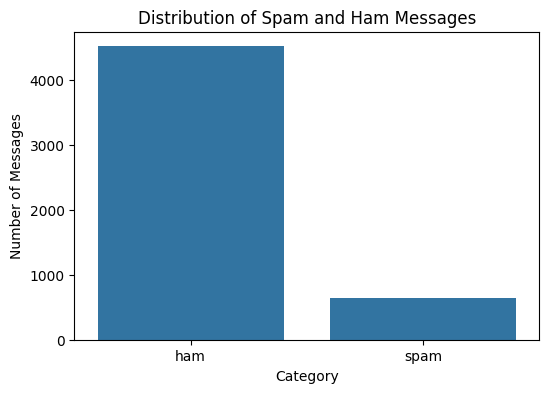

Category
ham     4516
spam     641
Name: count, dtype: int64


In [ ]:
# Distribution of spam and ham
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Category")
plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Category")
plt.ylabel("Number of Messages")
plt.show()

print(df["Category"].value_counts())


Category
ham     87.57
spam    12.43
Name: proportion, dtype: float64


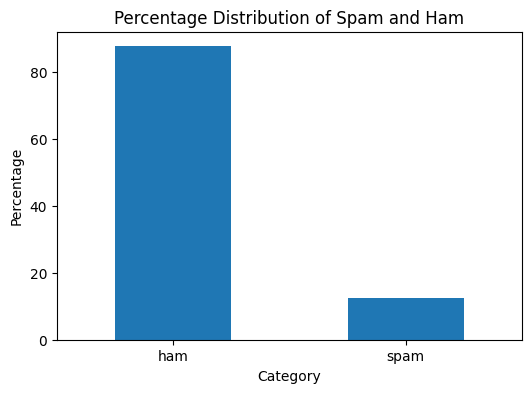

In [ ]:
# Percentage distribution
class_percent = df["Category"].value_counts(normalize=True) * 100
print(class_percent.round(2))

plt.figure(figsize=(6,4))
class_percent.plot(kind="bar")
plt.title("Percentage Distribution of Spam and Ham")
plt.xlabel("Category")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()


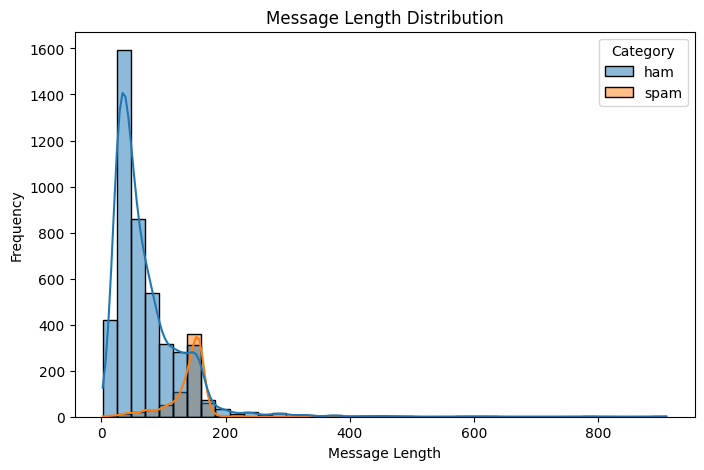

In [ ]:
# Message length distribution
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="message_length", hue="Category", bins=40, kde=True)
plt.title("Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")
plt.show()


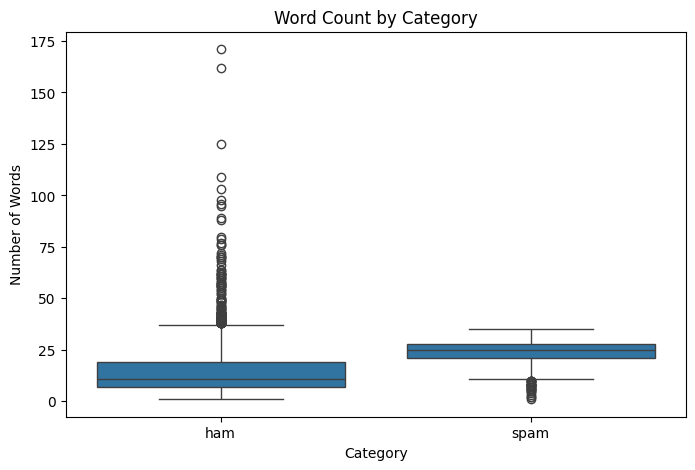

In [ ]:
# Word count distribution
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Category", y="word_count")
plt.title("Word Count by Category")
plt.xlabel("Category")
plt.ylabel("Number of Words")
plt.show()


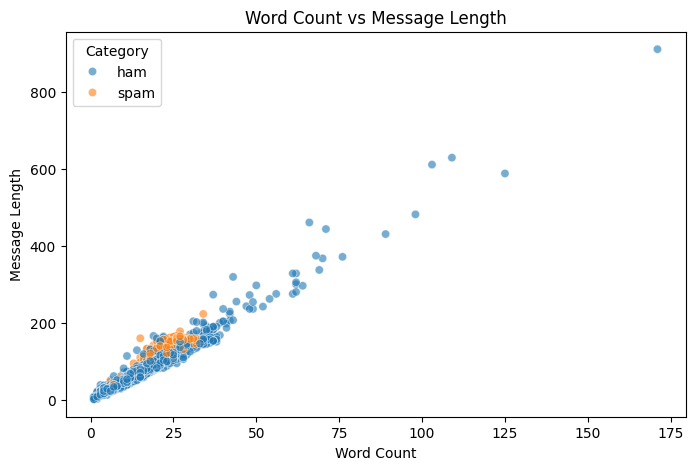

In [ ]:
# Relationship between message length and word count
plt.figure(figsize=(8,5))
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=42),
                x="word_count", y="message_length", hue="Category", alpha=0.6)
plt.title("Word Count vs Message Length")
plt.xlabel("Word Count")
plt.ylabel("Message Length")
plt.show()


In [ ]:
# Average text features by class
summary = df.groupby("Category")[["message_length", "word_count"]].mean().round(2)
display(summary)


,message_length,word_count
Category,,
ham,70.95,14.24
spam,137.54,23.66


### EDA Findings

- The dataset contains two classes: **ham** and **spam**.
- The classes are imbalanced, with ham messages forming the majority.
- Spam messages can show different text-length and word-count patterns from ham messages.
- Text content itself is expected to be more useful than only message length for classification.
- Therefore, NLP-based feature extraction is used in the next sprint.


# Sprint 1 – Preprocessing

## 1. Train-Test Split

The data is divided into training and testing sets. A stratified split is used so that both sets maintain a similar spam/ham class distribution.


In [ ]:
from sklearn.model_selection import train_test_split

X = df["Message"]
y = df["Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training samples: 4125
Testing samples: 1032

Training class distribution:
Category
ham     0.876
spam    0.124
Name: proportion, dtype: float64

Testing class distribution:
Category
ham     0.876
spam    0.124
Name: proportion, dtype: float64


## 2. Feature Engineering and Text Preprocessing

For SMS classification, the text must be converted into numerical features.

The main steps are:
- Convert text to lowercase.
- Remove unnecessary stop words.
- Generate unigram and bigram features.
- Convert text into TF-IDF numerical vectors.

### Why TF-IDF?
TF-IDF gives higher importance to words that are useful for distinguishing documents while reducing the importance of very common words.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)


Training TF-IDF shape: (4125, 31235)
Testing TF-IDF shape: (1032, 31235)


# Sprint 2 – Model Development

We train machine learning models on the TF-IDF features.

Models used:
1. Logistic Regression
2. Multinomial Naive Bayes

The models are evaluated using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
lr_pred = lr_model.predict(X_test_tfidf)

# Train Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)


In [ ]:
def evaluate_model(name, y_true, y_pred):
    print("=" * 60)
    print(name)
    print("=" * 60)
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, pos_label="spam"), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, pos_label="spam"), 4))
    print("F1-score :", round(f1_score(y_true, y_pred, pos_label="spam"), 4))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

evaluate_model("Logistic Regression", y_test, lr_pred)
evaluate_model("Multinomial Naive Bayes", y_test, nb_pred)


Logistic Regression
Accuracy : 0.9583
Precision: 0.9885
Recall   : 0.6719
F1-score : 0.8

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       0.99      0.67      0.80       128

    accuracy                           0.96      1032
   macro avg       0.97      0.84      0.89      1032
weighted avg       0.96      0.96      0.95      1032

Multinomial Naive Bayes
Accuracy : 0.9554
Precision: 1.0
Recall   : 0.6406
F1-score : 0.781

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       904
        spam       1.00      0.64      0.78       128

    accuracy                           0.96      1032
   macro avg       0.98      0.82      0.88      1032
weighted avg       0.96      0.96      0.95      1032



In [ ]:
# Compare the models using a metric table
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, nb_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred, pos_label="spam"),
        precision_score(y_test, nb_pred, pos_label="spam")
    ],
    "Recall": [
        recall_score(y_test, lr_pred, pos_label="spam"),
        recall_score(y_test, nb_pred, pos_label="spam")
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred, pos_label="spam"),
        f1_score(y_test, nb_pred, pos_label="spam")
    ]
})

display(results.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9583,0.9885,0.6719,0.800
1,Multinomial Naive Bayes,0.9554,1.0000,0.6406,0.781


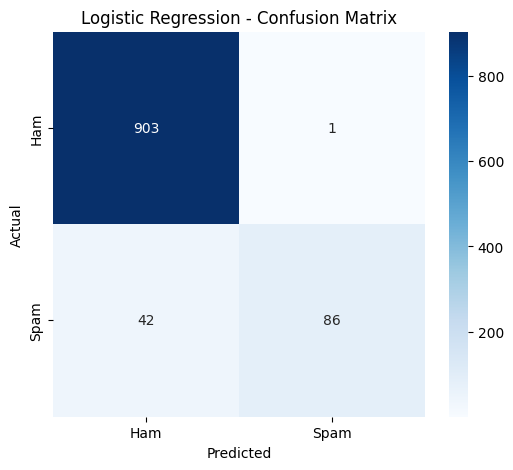

In [ ]:
# Confusion matrix for Logistic Regression
cm = confusion_matrix(y_test, lr_pred, labels=["ham", "spam"])

plt.figure(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


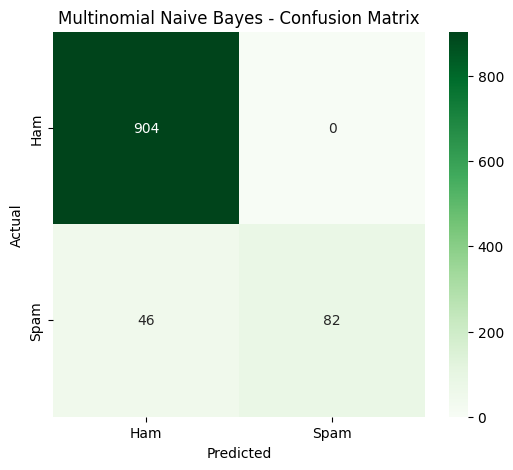

In [ ]:
# Confusion matrix for Naive Bayes
cm_nb = confusion_matrix(y_test, nb_pred, labels=["ham", "spam"])

plt.figure(figsize=(6,5))
sns.heatmap(
    cm_nb, annot=True, fmt="d", cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.title("Multinomial Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Model Evaluation Interpretation

- **Accuracy** measures the percentage of all correctly classified messages.
- **Precision for spam** measures how many messages predicted as spam are actually spam.
- **Recall for spam** measures how many actual spam messages were detected.
- **F1-score** balances precision and recall.
- The confusion matrix shows true positives, true negatives, false positives and false negatives.

For spam detection, precision and recall are both important because incorrectly marking a genuine message as spam and failing to detect spam are different types of errors.


# Sprint 3 – NLP Architecture Development

## Proposed NLP Architecture

**SMS Message → Text Cleaning → TF-IDF Vectorization → ML Classifier → Spam/Ham Prediction**

### Components

1. **Input Layer:** User enters an SMS message.
2. **Text Preprocessing:** Lowercase conversion and removal of unnecessary terms.
3. **Feature Extraction:** TF-IDF converts the message into numerical features.
4. **Classification Layer:** Logistic Regression or Multinomial Naive Bayes predicts the class.
5. **Output Layer:** The system displays `SPAM` or `HAM`.

This architecture is lightweight and suitable for real-time SMS classification.


In [ ]:
# Build an end-to-end NLP pipeline
from sklearn.pipeline import Pipeline

nlp_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB())
])

nlp_pipeline.fit(X_train, y_train)

pipeline_pred = nlp_pipeline.predict(X_test)

print("NLP Pipeline Evaluation")
print("Accuracy :", round(accuracy_score(y_test, pipeline_pred), 4))
print("Precision:", round(precision_score(y_test, pipeline_pred, pos_label="spam"), 4))
print("Recall   :", round(recall_score(y_test, pipeline_pred, pos_label="spam"), 4))
print("F1-score :", round(f1_score(y_test, pipeline_pred, pos_label="spam"), 4))


NLP Pipeline Evaluation
Accuracy : 0.9554
Precision: 1.0
Recall   : 0.6406
F1-score : 0.781


In [ ]:
# Test the NLP architecture with new messages
test_messages = [
    "Congratulations! You won a free prize. Call now to claim it!",
    "Hi, are we still meeting at 6 pm today?",
    "URGENT! You have won a cash reward. Click the link to claim.",
    "Please bring the assignment tomorrow."
]

predictions = nlp_pipeline.predict(test_messages)

for message, prediction in zip(test_messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-" * 70)


Message: Congratulations! You won a free prize. Call now to claim it!
Prediction: SPAM
----------------------------------------------------------------------
Message: Hi, are we still meeting at 6 pm today?
Prediction: HAM
----------------------------------------------------------------------
Message: URGENT! You have won a cash reward. Click the link to claim.
Prediction: SPAM
----------------------------------------------------------------------
Message: Please bring the assignment tomorrow.
Prediction: HAM
----------------------------------------------------------------------


# Sprint 4 – Model Deployment

The trained NLP pipeline can be deployed as a simple web application using **Streamlit**.

## Deployment architecture

**User → Streamlit UI → NLP Pipeline → Prediction → Result**

The following code can be saved as `app.py`. The trained pipeline is saved as a model file and loaded by the application.


In [ ]:
# Save the complete NLP pipeline
import joblib

joblib.dump(nlp_pipeline, "spam_ham_model.pkl")
print("Model saved as spam_ham_model.pkl")


Model saved as spam_ham_model.pkl


## Streamlit Deployment Code

Create a file named **`app.py`** with the following code:

```python
import streamlit as st
import joblib

model = joblib.load("spam_ham_model.pkl")

st.title("Spam and Ham Message Detector")
st.write("Enter an SMS message to classify it as spam or ham.")

message = st.text_area("Enter your message:")

if st.button("Predict"):
    if message.strip():
        prediction = model.predict([message])[0]

        if prediction == "spam":
            st.error("Prediction: SPAM")
        else:
            st.success("Prediction: HAM")
    else:
        st.warning("Please enter a message.")
```

### Run the application

Install the required packages:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit
```

Then run:

```bash
streamlit run app.py
```


# Final Project Summary

## Objective
To build an NLP-based machine learning system that classifies SMS messages into spam and ham categories.

## Process
1. Loaded and understood the dataset.
2. Checked missing values and duplicate records.
3. Performed data cleaning.
4. Created message length and word-count features for EDA.
5. Visualized class distribution and text characteristics.
6. Split the dataset into training and testing sets.
7. Converted text into TF-IDF features.
8. Trained Logistic Regression and Multinomial Naive Bayes models.
9. Evaluated the models using accuracy, precision, recall, F1-score and confusion matrices.
10. Built an end-to-end NLP pipeline.
11. Saved the trained pipeline for deployment.
12. Provided a Streamlit deployment approach.

## Conclusion
The project demonstrates how Natural Language Processing and machine learning can be used to automatically identify unwanted SMS messages. TF-IDF provides numerical text features, while supervised classification models learn the difference between spam and ham messages. The final pipeline can be integrated into a simple web application for real-time prediction.


# Requirements

Install these libraries before running the notebook if required:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn joblib
```

For deployment:

```bash
pip install streamlit
```
